PRCP-1001: Rice Leaf Disease Detection

Objective: Classify rice leaf images into three disease classes, and report on the data, the augmentation techniques, the model comparison and the challenges.

Author: DEENA JOSE Date: 10-11-2026

# Rice Leaf Disease Classification

### Dataset analysis · augmentation study · four-model benchmark · deployment recommendation

**Project:** PRCP-1001 RiceLeaf  
**Task:** Classify a rice-leaf image into one of three disease categories.  
**Classes:** Leaf smut · Brown spot · Bacterial leaf blight  
**Dataset described in the brief:** 120 JPG images, 40 per class.

> **Label discrepancy:** The model task sentence in the brief names leaf blast, while its dataset class list names Leaf smut. This notebook treats the actual dataset folder names as ground truth. It does not silently relabel images. Verify any different folder names before changing the class mapping.

This notebook is a reproducible analysis and training workflow. It contains **exactly four model approaches**: a compact CNN trained from scratch, plus MobileNetV2, EfficientNetB0, and ResNet50 with ImageNet transfer learning. It includes no pre-filled performance claims; all reported metrics are generated by running the notebook on your dataset.

Run from top to bottom. The pretrained models download ImageNet weights on first use, so internet access is required for that step. CPU training works but may take a while; a GPU is optional.


## 1. Environment setup

Create a Python environment and install the notebook dependencies. TensorFlow installation differs by operating system and accelerator; consult the official TensorFlow installation instructions if the command is unsuitable for your computer.

    python -m pip install --upgrade pip
    python -m pip install tensorflow numpy pandas matplotlib seaborn scikit-learn pillow jupyter

The next cell records versions actually used by the active notebook kernel.


In [1]:
import sys, platform, importlib.metadata as metadata
print("Python:", sys.version.split()[0], "| Platform:", platform.platform())
for package in ["tensorflow", "numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "pillow"]:
    try: print(f"{package:16s} {metadata.version(package)}")
    except metadata.PackageNotFoundError: print(f"{package:16s} NOT INSTALLED")


Python: 3.10.11 | Platform: Windows-10-10.0.26300-SP0
tensorflow       2.21.0
numpy            2.2.6
pandas           2.3.3
matplotlib       3.10.9
seaborn          0.13.2
scikit-learn     1.7.2
pillow           12.3.0


## 2. Dataset location and setup

Extract the supplied archive so the configured directory contains a folder per class, with JPG images inside. For example:

    data/images/
    ├── Bacterial leaf blight/  (40 JPG files)
    ├── Brown spot/             (40 JPG files)
    └── Leaf smut/              (40 JPG files)

The project brief links to PRCP-1001-RiceLeaf.zip. The reference notebook describes a package that may contain three class-specific ZIP archives; extract both levels. Set DATASET_DIR to the directory whose immediate children are the class folders. Paths may be absolute or relative to this notebook.


In [2]:
from pathlib import Path
import os, random, hashlib, warnings, time, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image, UnidentifiedImageError
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore", category=UserWarning)
SEED=42; random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
try: tf.config.experimental.enable_op_determinism()
except Exception: pass
sns.set_theme(style="whitegrid", context="notebook")
DATASET_DIR=Path("data/images")  # EDIT THIS if the folders are elsewhere
OUTPUT_DIR=Path("outputs"); OUTPUT_DIR.mkdir(exist_ok=True)
CLASS_NAMES=["Leaf smut", "Brown spot", "Bacterial leaf blight"]
IMG_SIZE=(128,128); BATCH_SIZE=4
print("TensorFlow:",tf.__version__)
print("Dataset:",DATASET_DIR.resolve())
print("Visible GPUs:",tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
Dataset: C:\Users\DEENA\Downloads\data\images
Visible GPUs: []


In [3]:
import zipfile

ZIP_PATH=Path("PRCP-1001-RiceLeaf.zip")  # change to the downloaded ZIP's full path if needed
RAW_DIR=Path("data/raw")

def safe_extract(zip_path, destination):
    destination=destination.resolve()
    with zipfile.ZipFile(zip_path) as zf:
        for member in zf.infolist():
            target=(destination/member.filename).resolve()
            if target!=destination and destination not in target.parents:
                raise ValueError(f"Unsafe path in archive: {member.filename}")
            if member.is_dir(): target.mkdir(parents=True,exist_ok=True)
            else:
                target.parent.mkdir(parents=True,exist_ok=True)
                with zf.open(member) as source, target.open("wb") as sink:
                    sink.write(source.read())

def class_for_archive(archive_path):
    label_text=(str(archive_path.parent)+" "+archive_path.stem).casefold().replace("_"," ").replace("-"," ")
    for label in CLASS_NAMES:
        if label.casefold() in label_text: return label
    return None

if DATASET_DIR.is_dir():
    print("Using existing dataset folder:",DATASET_DIR.resolve())
elif ZIP_PATH.is_file():
    RAW_DIR.mkdir(parents=True,exist_ok=True)
    safe_extract(ZIP_PATH,RAW_DIR)
    DATASET_DIR.mkdir(parents=True,exist_ok=True)
    class_zips=list(RAW_DIR.rglob("*.zip"))
    extracted=[]
    for archive in class_zips:
        label=class_for_archive(archive)
        if label:
            safe_extract(archive,DATASET_DIR/label)
            extracted.append(label)
    # Directories bundled in the outer ZIP may already contain the class folders.
    expected={x.casefold() for x in CLASS_NAMES}
    candidates=[RAW_DIR]+[q for q in RAW_DIR.rglob("*") if q.is_dir()]
    folder_root=next((q for q in candidates if expected.issubset({x.name.casefold() for x in q.iterdir() if x.is_dir()})),None)
    if folder_root and not any((DATASET_DIR/x).exists() for x in CLASS_NAMES):
        DATASET_DIR=folder_root
    print("ZIP extraction complete. Dataset folder:",DATASET_DIR.resolve())
    print("Class archives extracted:",sorted(set(extracted)))
else:
    print("ZIP not found at:",ZIP_PATH.resolve())
    print("Set DATASET_DIR to the already-extracted folder, or set ZIP_PATH to your downloaded archive and rerun this cell.")

ZIP extraction complete. Dataset folder: C:\Users\DEENA\Downloads\data\images
Class archives extracted: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']


## 3. Dataset inventory and data-quality checks

The brief describes 120 JPGs and 40 images per class. This inventory uses observed files and checks folder names, readable images, dimensions, colour modes, and exact duplicates. Review any duplicates before interpreting a random split: identical files in both train and test would inflate scores.


In [4]:
if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f"Dataset folder missing: {DATASET_DIR.resolve()}. Extract the archive and set DATASET_DIR.")
IMG_EXT={".jpg",".jpeg",".png"}
folder_map={p.name.strip().casefold():p for p in DATASET_DIR.iterdir() if p.is_dir()}
missing=[n for n in CLASS_NAMES if n.casefold() not in folder_map]
extra=[p.name for k,p in folder_map.items() if k not in {n.casefold() for n in CLASS_NAMES}]
if missing or extra: raise ValueError(f"Folder mismatch. Missing={missing}; additional={extra}. Verify labels before changing CLASS_NAMES.")
records=[]; unreadable=[]
for label_id,label in enumerate(CLASS_NAMES):
    for p in sorted(folder_map[label.casefold()].rglob("*")):
        if not p.is_file() or p.suffix.casefold() not in IMG_EXT: continue
        try:
            digest=hashlib.sha256(p.read_bytes()).hexdigest()
            with Image.open(p) as im: im.verify()
            with Image.open(p) as im: w,h,mode=im.width,im.height,im.mode
            records.append(dict(path=str(p),label=label,label_id=label_id,filename=p.name,width=w,height=h,aspect_ratio=w/h,mode=mode,sha256=digest))
        except (OSError,UnidentifiedImageError,ValueError) as e: unreadable.append({"path":str(p),"error":str(e)})
df=pd.DataFrame(records)
if df.empty: raise ValueError("No readable images found. Check DATASET_DIR and class subfolders.")
counts=df.groupby("label").size().reindex(CLASS_NAMES,fill_value=0)
print(f"Readable images: {len(df)} (brief: 120)"); display(counts.rename("images").to_frame())
print("Unreadable:",len(unreadable),"| distinct dimensions:",df[["width","height"]].drop_duplicates().shape[0],"| modes:",df["mode"].value_counts().to_dict())
dups=df[df.duplicated("sha256",keep=False)].sort_values("sha256")
print("Files in exact-duplicate groups:",len(dups))
if unreadable: display(pd.DataFrame(unreadable))
if len(dups): display(dups[["path","label","sha256"]])



Readable images: 119 (brief: 120)


,images
label,
Leaf smut,39
Brown spot,40
Bacterial leaf blight,40


Unreadable: 0 | distinct dimensions: 34 | modes: {'RGB': 119}
Files in exact-duplicate groups: 0


### 3.1 Descriptive analysis

The plots and summary describe the observed class balance, image geometry and variability. Image dimensions and aspect ratios influence how much leaf detail survives resizing. The preprocessing below pads images to a square, avoiding distortion of long leaves.


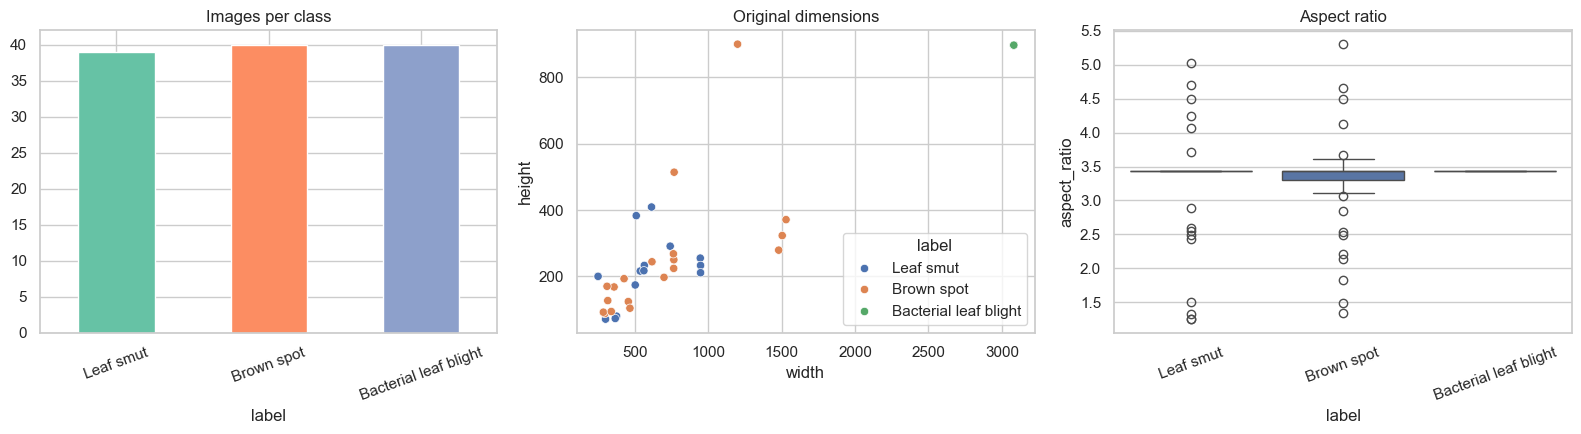

,images,mean_width,median_width,mean_height,median_aspect
label,,,,,
Bacterial leaf blight,40,3081.00,3081.0,897.00,3.43
Brown spot,40,1951.28,3081.0,589.17,3.43
Leaf smut,39,2111.85,3081.0,635.23,3.43


In [5]:
fig,ax=plt.subplots(1,3,figsize=(16,4.5))
counts.plot(kind="bar",color=sns.color_palette("Set2",len(CLASS_NAMES)),ax=ax[0]); ax[0].set_title("Images per class"); ax[0].tick_params(axis="x",rotation=20)
sns.scatterplot(data=df,x="width",y="height",hue="label",hue_order=CLASS_NAMES,ax=ax[1]); ax[1].set_title("Original dimensions")
sns.boxplot(data=df,x="label",y="aspect_ratio",order=CLASS_NAMES,ax=ax[2]); ax[2].set_title("Aspect ratio"); ax[2].tick_params(axis="x",rotation=20)
plt.tight_layout(); plt.show()
display(df.groupby("label").agg(images=("path","count"),mean_width=("width","mean"),median_width=("width","median"),mean_height=("height","mean"),median_aspect=("aspect_ratio","median")).round(2))


### 3.2 Visual sample review

Inspect original examples for mislabeled or ambiguous leaves, backgrounds, image artefacts, and visible disease cues. On a small dataset, one unusual image can materially affect a held-out score.


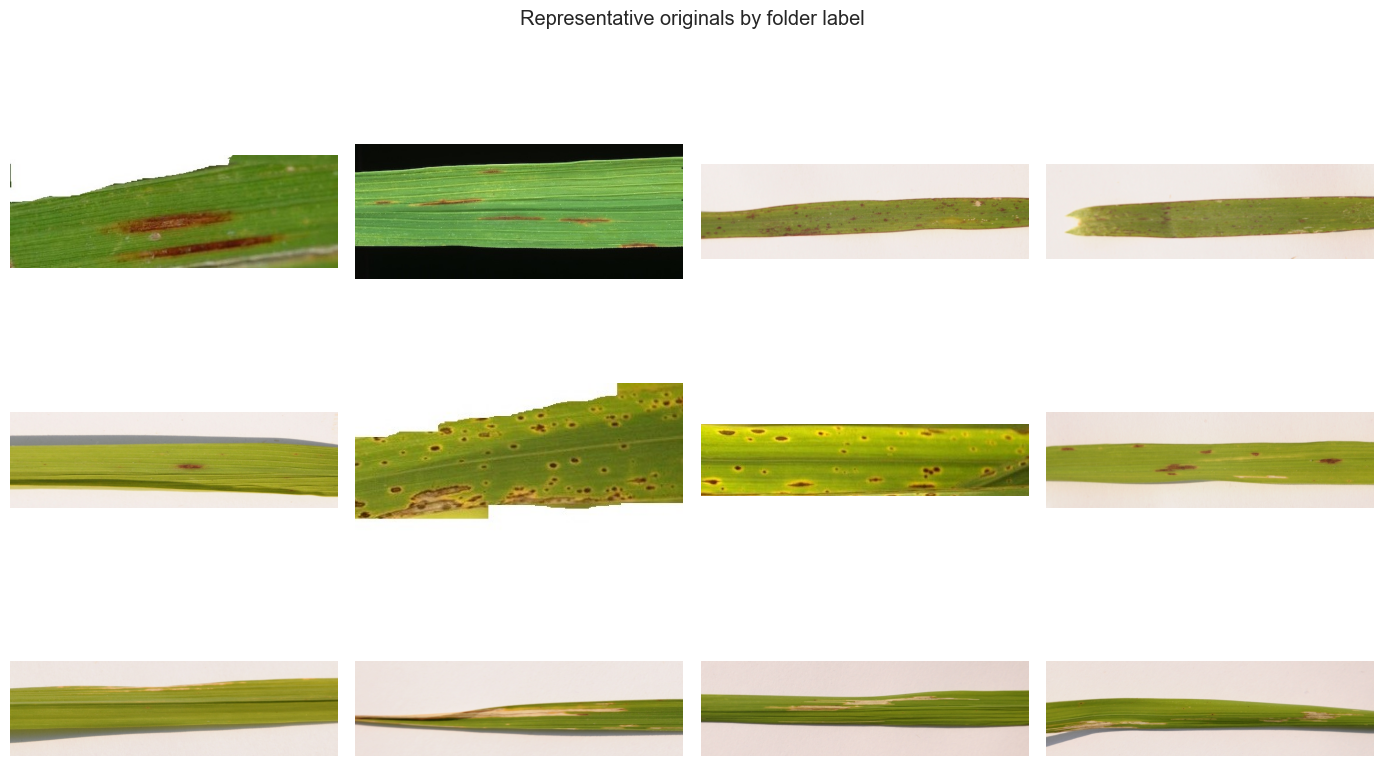

OBSERVED REPORT: 119 readable images; counts: {'Leaf smut': 39, 'Brown spot': 40, 'Bacterial leaf blight': 40}
Unreadable files: 0 | duplicate-group files: 0
Review: observed counts differ from brief's 120 / 40-per-class description.


In [6]:
fig,axes=plt.subplots(3,4,figsize=(14,9))
for r,label in enumerate(CLASS_NAMES):
    sample=df[df.label==label].sample(n=min(4,(df.label==label).sum()),random_state=SEED)
    for c,ax in enumerate(axes[r]):
        ax.axis("off")
        if c<len(sample):
            with Image.open(sample.iloc[c].path) as im: ax.imshow(im.convert("RGB"))
            if c==0: ax.set_ylabel(label,fontweight="bold")
plt.suptitle("Representative originals by folder label"); plt.tight_layout(); plt.show()
print("OBSERVED REPORT:",len(df),"readable images; counts:",counts.to_dict())
print("Unreadable files:",len(unreadable),"| duplicate-group files:",len(dups))
if len(df)!=120 or (counts!=40).any(): print("Review: observed counts differ from brief's 120 / 40-per-class description.")


## 4. Leakage-safe split and common preprocessing

Split the images before random augmentation. A stratified 70/15/15 partition reserves a small validation set for model selection and a test set for final reporting. With about 18 test images, one image changes accuracy by roughly 5.6 percentage points; include supports and macro-F1, and treat scores as uncertain. Exact duplicates identified above must be reviewed because this random split does not group duplicate photographs.

All approaches use the same RGB input, square letterboxing, image size and split.


In [7]:
paths=df.path.to_numpy(); y=df.label_id.to_numpy(dtype=np.int32); idx=np.arange(len(df))
train_idx,tmp_idx=train_test_split(idx,test_size=.30,random_state=SEED,stratify=y)
val_idx,test_idx=train_test_split(tmp_idx,test_size=.50,random_state=SEED,stratify=y[tmp_idx])
def letterbox(p,size=IMG_SIZE):
    with Image.open(p) as im:
        im=im.convert("RGB"); im.thumbnail((size[1],size[0]),Image.Resampling.BILINEAR)
        canvas=Image.new("RGB",(size[1],size[0]),(0,0,0)); canvas.paste(im,((size[1]-im.width)//2,(size[0]-im.height)//2))
        return np.asarray(canvas,dtype=np.uint8)
X=np.stack([letterbox(p) for p in paths])
X_train,y_train=X[train_idx],y[train_idx]; X_val,y_val=X[val_idx],y[val_idx]; X_test,y_test=X[test_idx],y[test_idx]
split_counts=pd.DataFrame({"train":np.bincount(y_train,minlength=3),"validation":np.bincount(y_val,minlength=3),"test":np.bincount(y_test,minlength=3)},index=CLASS_NAMES)
display(split_counts); print("Shapes:",X_train.shape,X_val.shape,X_test.shape)
print("Partition indices disjoint:",not(set(train_idx)&set(val_idx) or set(train_idx)&set(test_idx) or set(val_idx)&set(test_idx)))


,train,validation,test
Leaf smut,27,6,6
Brown spot,28,6,6
Bacterial leaf blight,28,6,6


Shapes: (83, 128, 128, 3) (18, 128, 128, 3) (18, 128, 128, 3)
Partition indices disjoint: True


## 5. Augmentation and other techniques

Augmentation runs only on training batches. The mild transforms below vary framing and lighting: horizontal reflection, small rotation, translation, zoom and contrast. Aggressive cropping or colour shifts may erase lesions or alter useful colour cues, so inspect transformed samples.

MobileNetV2, EfficientNetB0 and ResNet50 reuse ImageNet features. Their classifier heads train first with frozen backbones, then only a short backbone tail is fine-tuned at a low learning rate. The compact CNN is a from-scratch baseline. Early stopping, learning-rate reduction and dropout reduce unnecessary fitting; they cannot replace more diverse images.


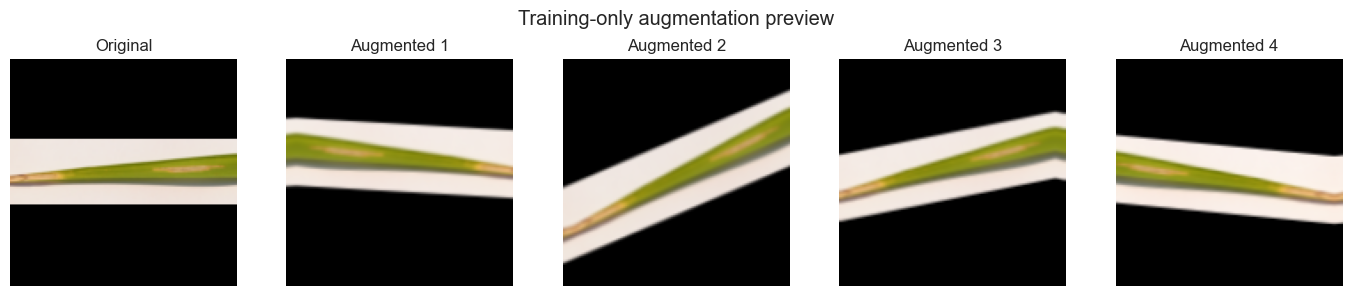

In [8]:
def augmentation_layers():
    return tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal",seed=SEED),
        tf.keras.layers.RandomRotation(.08,seed=SEED+1),
        tf.keras.layers.RandomTranslation(.06,.06,seed=SEED+2),
        tf.keras.layers.RandomZoom(.08,seed=SEED+3),
        tf.keras.layers.RandomContrast(.10,seed=SEED+4)],name="training_augmentation")
aug=augmentation_layers(); fig,axes=plt.subplots(1,5,figsize=(14,3))
axes[0].imshow(X_train[0]); axes[0].set_title("Original")
for i,ax in enumerate(axes[1:]):
    a=aug(tf.cast(X_train[:1],tf.float32),training=True)[0].numpy()
    ax.imshow(np.clip(a/255,0,1)); ax.set_title(f"Augmented {i+1}")
for ax in axes: ax.axis("off")
plt.suptitle("Training-only augmentation preview"); plt.tight_layout(); plt.show()


### Augmentation and technique analysis

| Technique | Intended benefit | Risk / interpretation |
|---|---|---|
| Horizontal reflection | Reduce sensitivity to left/right orientation | Check that orientation is not a collection cue |
| Mild rotation / translation | Vary camera framing | Large movements can hide lesions |
| Mild zoom | Add scale variation | Crops may remove diagnostic context |
| Mild contrast | Add limited illumination variation | Colour changes may obscure symptoms |
| Aspect-preserving padding | Keep long leaves undistorted | Black borders may become a spurious cue |
| ImageNet transfer learning | Reuse general visual features with few labels | Source images differ from rice leaves |
| Frozen head then low-rate fine-tuning | Adapt high-level features gradually | Unfreezing too much can overfit |
| Early stopping and dropout | Limit memorization | Do not replace external validation |

The preview is a qualitative augmentation audit. Model scores below measure the full recipe; they do not isolate the causal benefit of each transform. To claim that augmentation improves performance, compare the same architecture, split, budget and seeds with augmentation on versus off, preferably across repeated stratified folds.


## 6. Four model approaches

All four approaches use the same labels, image size, partitions, augmentation, callbacks and metrics. Application-specific input preprocessing is included inside each pretrained model.

1. **Compact CNN** — trained from scratch as a baseline.
2. **MobileNetV2** — lightweight transfer-learning approach.
3. **EfficientNetB0** — transfer-learning benchmark.
4. **ResNet50** — residual-network transfer-learning benchmark.

ImageNet weights download on first use. Defaults use a short run for practicality; increase epochs only when curves show progress without a widening validation gap.


In [9]:
NUM_CLASSES=3
MODEL_NAMES=["CustomCNN","MobileNetV2","EfficientNetB0","ResNet50"]
assert len(MODEL_NAMES)==4 and len(set(MODEL_NAMES))==4
EPOCHS_HEAD=8; EPOCHS_FINETUNE=5

def make_model(name):
    inputs=tf.keras.Input(shape=(*IMG_SIZE,3),name="rgb_0_255")
    x=augmentation_layers()(inputs)
    if name=="CustomCNN":
        x=tf.keras.layers.Rescaling(1./255)(x)
        for f in (32,64,128):
            x=tf.keras.layers.Conv2D(f,3,padding="same",use_bias=False)(x)
            x=tf.keras.layers.BatchNormalization()(x); x=tf.keras.layers.Activation("relu")(x); x=tf.keras.layers.MaxPooling2D()(x)
        x=tf.keras.layers.GlobalAveragePooling2D()(x); x=tf.keras.layers.Dropout(.35)(x)
        return tf.keras.Model(inputs,tf.keras.layers.Dense(3,activation="softmax")(x),name=name)
    apps={
      "MobileNetV2":(tf.keras.applications.MobileNetV2,tf.keras.applications.mobilenet_v2.preprocess_input),
      "EfficientNetB0":(tf.keras.applications.EfficientNetB0,tf.keras.applications.efficientnet.preprocess_input),
      "ResNet50":(tf.keras.applications.ResNet50,tf.keras.applications.resnet50.preprocess_input)}
    constructor,preprocess=apps[name]
    x=tf.keras.layers.Lambda(preprocess,name="application_preprocess")(x)
    backbone=constructor(include_top=False,weights="imagenet",input_shape=(*IMG_SIZE,3)); backbone.trainable=False
    x=backbone(x,training=False); x=tf.keras.layers.GlobalAveragePooling2D()(x); x=tf.keras.layers.Dropout(.30)(x)
    model=tf.keras.Model(inputs,tf.keras.layers.Dense(3,activation="softmax")(x),name=name)
    model.backbone=backbone
    return model


### 6.1 Fit all four approaches

Transfer models train the new head, then unfreeze the last 20 backbone layers while keeping batch-normalization layers frozen. The same validation callbacks are used. Training time reflects your hardware, not a universal speed comparison.


In [10]:
def fit_model(name):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    model=make_model(name)
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=8,restore_best_weights=True),
               tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=.25,patience=2,min_lr=1e-6)]
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    start=time.perf_counter()
    h1=model.fit(X_train,y_train,validation_data=(X_val,y_val),epochs=EPOCHS_HEAD,batch_size=BATCH_SIZE,callbacks=callbacks,verbose=1)
    logs=[h1.history]
    if name!="CustomCNN":
        b=model.backbone; b.trainable=True
        for layer in b.layers[:-20]: layer.trainable=False
        for layer in b.layers:
            if isinstance(layer,tf.keras.layers.BatchNormalization): layer.trainable=False
        model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),loss="sparse_categorical_crossentropy",metrics=["accuracy"])
        h2=model.fit(X_train,y_train,validation_data=(X_val,y_val),epochs=EPOCHS_FINETUNE,batch_size=BATCH_SIZE,callbacks=callbacks,verbose=1)
        logs.append(h2.history)
    return model,logs,time.perf_counter()-start
models={}; histories={}; train_seconds={}
for name in MODEL_NAMES:
    print("\n", "="*15, name, "="*15)
    models[name],histories[name],train_seconds[name]=fit_model(name)
    print(f"Elapsed: {train_seconds[name]/60:.1f} min")



 =============== CustomCNN ===============

Epoch 1/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 13s 207ms/step - accuracy: 0.4096 - loss: 1.2414 - val_accuracy: 0.3333 - val_loss: 1.0943 - learning_rate: 0.0010
Epoch 2/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 180ms/step - accuracy: 0.4699 - loss: 1.0475 - val_accuracy: 0.5000 - val_loss: 1.0933 - learning_rate: 0.0010
Epoch 3/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 179ms/step - accuracy: 0.5301 - loss: 1.0178 - val_accuracy: 0.3333 - val_loss: 1.1368 - learning_rate: 0.0010
Epoch 4/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 168ms/step - accuracy: 0.5181 - loss: 0.9953 - val_accuracy: 0.3333 - val_loss: 1.2412 - learning_rate: 0.0010
Epoch 5/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 178ms/step - accuracy: 0.5783 - loss: 0.9279 - val_accuracy: 0.3333 - val_loss: 1.3850 - learning_rate: 2.5000e-04
Epoch 6/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 179ms/step - accuracy: 0.4940 - loss: 0.9504 - val_accuracy: 0.3333 - val_loss: 1.5871 - learning_rate: 2.5000e-04
Epoch 7/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 5s 

## 7. Training behaviour

Compare learning curves. A widening training–validation gap suggests overfitting; validation performance near chance suggests that the input pipeline, labels or model settings need review.


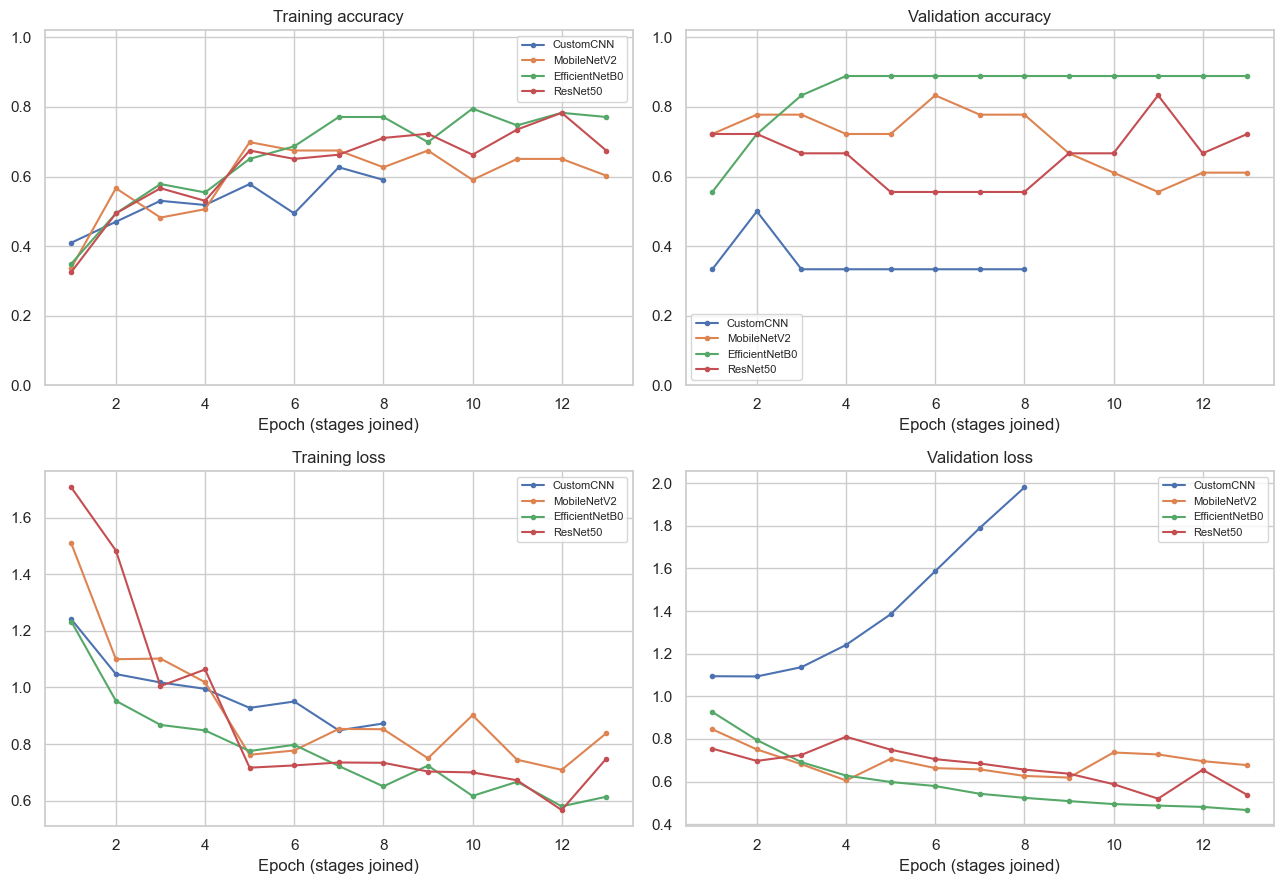

In [11]:
fig,axes=plt.subplots(2,2,figsize=(13,9))
for ax,metric,title in zip(axes.flat,["accuracy","val_accuracy","loss","val_loss"],["Training accuracy","Validation accuracy","Training loss","Validation loss"]):
    for name in MODEL_NAMES:
        values=[v for part in histories[name] for v in part.get(metric,[])]
        ax.plot(range(1,len(values)+1),values,marker=".",label=name)
    ax.set_title(title); ax.set_xlabel("Epoch (stages joined)"); ax.legend(fontsize=8)
    if "accuracy" in metric: ax.set_ylim(0,1.02)
plt.tight_layout(); plt.show()


## 8. Evaluation and four-model comparison

The candidate is selected using validation macro-F1, with validation accuracy as a tie-break. Test metrics are reported for transparency but should not be used to keep tuning. With this small test split, scores have wide uncertainty; report class supports and per-class metrics as well as accuracy.


In [12]:
def predict(model,images):
    p=model.predict(images,batch_size=BATCH_SIZE,verbose=0)
    return p,p.argmax(axis=1)
val_predictions={}; test_predictions={}; rows=[]
for name in MODEL_NAMES:
    vp,vy=predict(models[name],X_val); tp,ty=predict(models[name],X_test)
    val_predictions[name]=(vp,vy); test_predictions[name]=(tp,ty)
    rows.append({"model":name,"validation_accuracy":accuracy_score(y_val,vy),
      "validation_macro_f1":f1_score(y_val,vy,average="macro",zero_division=0),
      "test_accuracy":accuracy_score(y_test,ty),"test_balanced_accuracy":balanced_accuracy_score(y_test,ty),
      "test_macro_f1":f1_score(y_test,ty,average="macro",zero_division=0),
      "parameters":models[name].count_params(),"training_minutes":train_seconds[name]/60})
comparison=pd.DataFrame(rows).sort_values(["validation_macro_f1","validation_accuracy"],ascending=False).reset_index(drop=True)
display(comparison.round(3))


,model,validation_accuracy,validation_macro_f1,test_accuracy,test_balanced_accuracy,test_macro_f1,parameters,training_minutes
0,EfficientNetB0,0.889,0.882,0.722,0.722,0.693,4053414,2.155
1,ResNet50,0.833,0.831,0.833,0.833,0.836,23593859,3.818
2,MobileNetV2,0.667,0.646,0.778,0.778,0.770,2261827,1.406
3,CustomCNN,0.500,0.413,0.333,0.333,0.235,94307,0.703


### 8.1 Per-class metrics and confusion matrices

Confusion-matrix rows are true labels and columns are predictions. Per-class precision, recall and F1 show weaknesses that aggregate accuracy can hide.


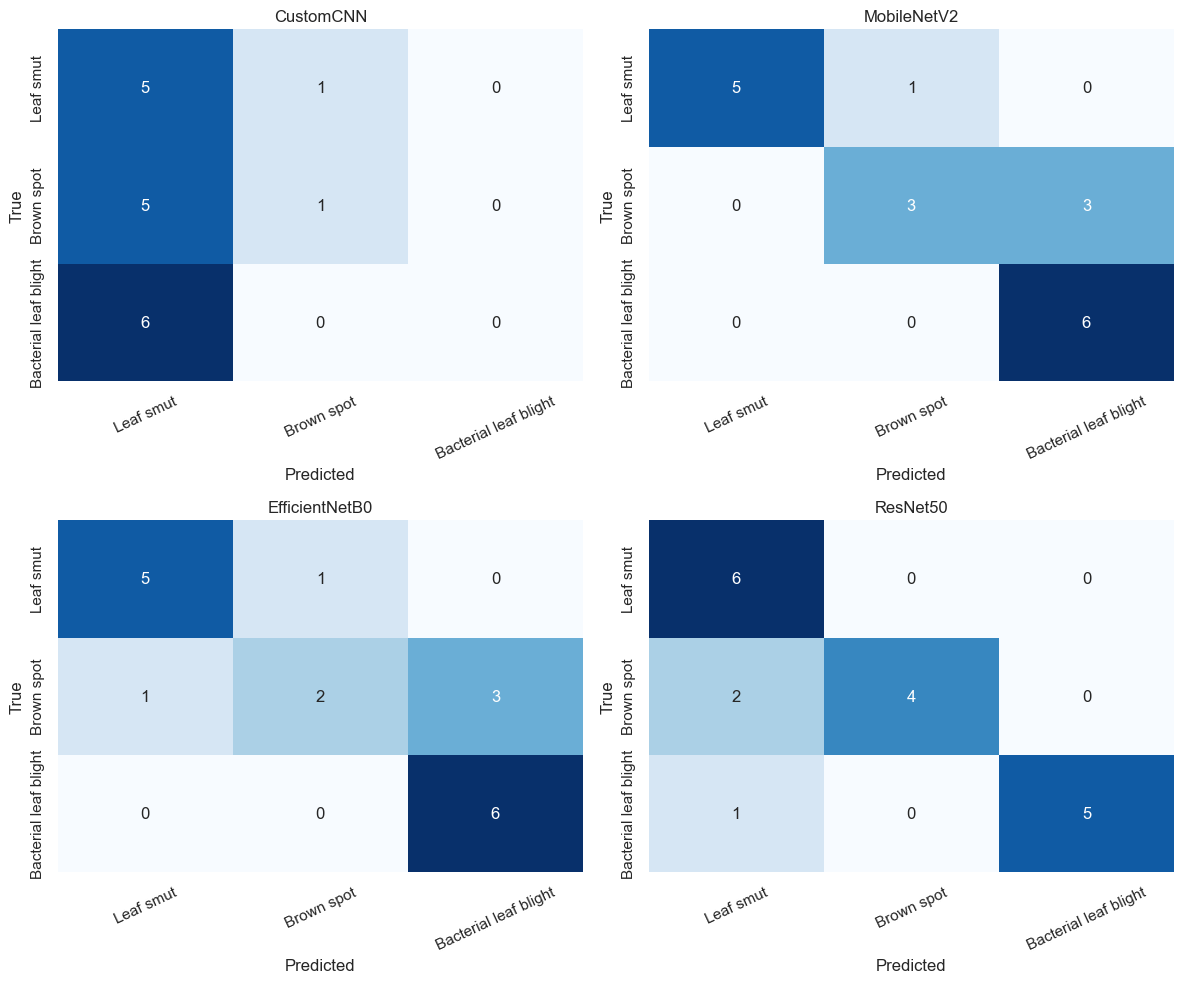


 CustomCNN — held-out test
                       precision    recall  f1-score   support

            Leaf smut      0.312     0.833     0.455         6
           Brown spot      0.500     0.167     0.250         6
Bacterial leaf blight      0.000     0.000     0.000         6

             accuracy                          0.333        18
            macro avg      0.271     0.333     0.235        18
         weighted avg      0.271     0.333     0.235        18


 MobileNetV2 — held-out test
                       precision    recall  f1-score   support

            Leaf smut      1.000     0.833     0.909         6
           Brown spot      0.750     0.500     0.600         6
Bacterial leaf blight      0.667     1.000     0.800         6

             accuracy                          0.778        18
            macro avg      0.806     0.778     0.770        18
         weighted avg      0.806     0.778     0.770        18


 EfficientNetB0 — held-out test
                     

In [13]:
fig,axes=plt.subplots(2,2,figsize=(12,10))
for ax,name in zip(axes.flat,MODEL_NAMES):
    cm=confusion_matrix(y_test,test_predictions[name][1],labels=np.arange(3))
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",cbar=False,xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.tick_params(axis="x",rotation=25)
plt.tight_layout(); plt.show()
for name in MODEL_NAMES:
    print("\n",name,"— held-out test")
    print(classification_report(y_test,test_predictions[name][1],target_names=CLASS_NAMES,labels=np.arange(3),zero_division=0,digits=3))
print("Test support:",dict(zip(CLASS_NAMES,np.bincount(y_test,minlength=3))))


### 8.2 Production recommendation

The next cell nominates the validation-selected model for further evaluation. It is not a deployment certification. Before production, collect images from different fields, cultivars, devices, lighting and disease stages; evaluate with site/group-based splits; test calibration and target-device latency; and include human review. Do not use this small-dataset classifier alone to make treatment decisions.


In [14]:
selected_name=comparison.iloc[0].model
selected=comparison.iloc[0]
print("Validation-selected candidate:",selected_name)
print(f"Validation macro-F1 {selected.validation_macro_f1:.3f}; validation accuracy {selected.validation_accuracy:.3f}")
print(f"Held-out test accuracy {selected.test_accuracy:.3f}; test macro-F1 {selected.test_macro_f1:.3f}")
print("Recommendation: leading candidate for external evaluation only; a single small random split cannot establish production readiness.")


Validation-selected candidate: EfficientNetB0
Validation macro-F1 0.882; validation accuracy 0.889
Held-out test accuracy 0.722; test macro-F1 0.693
Recommendation: leading candidate for external evaluation only; a single small random split cannot establish production readiness.


## 9. Error analysis

Inspect mistakes by the validation-selected candidate. Low-confidence errors may indicate ambiguity; high-confidence errors can point to label problems or model blind spots. Compare each prediction with the original image and verified folder label. Predictions do not automatically alter labels.


Misclassified test images: 5 / 18


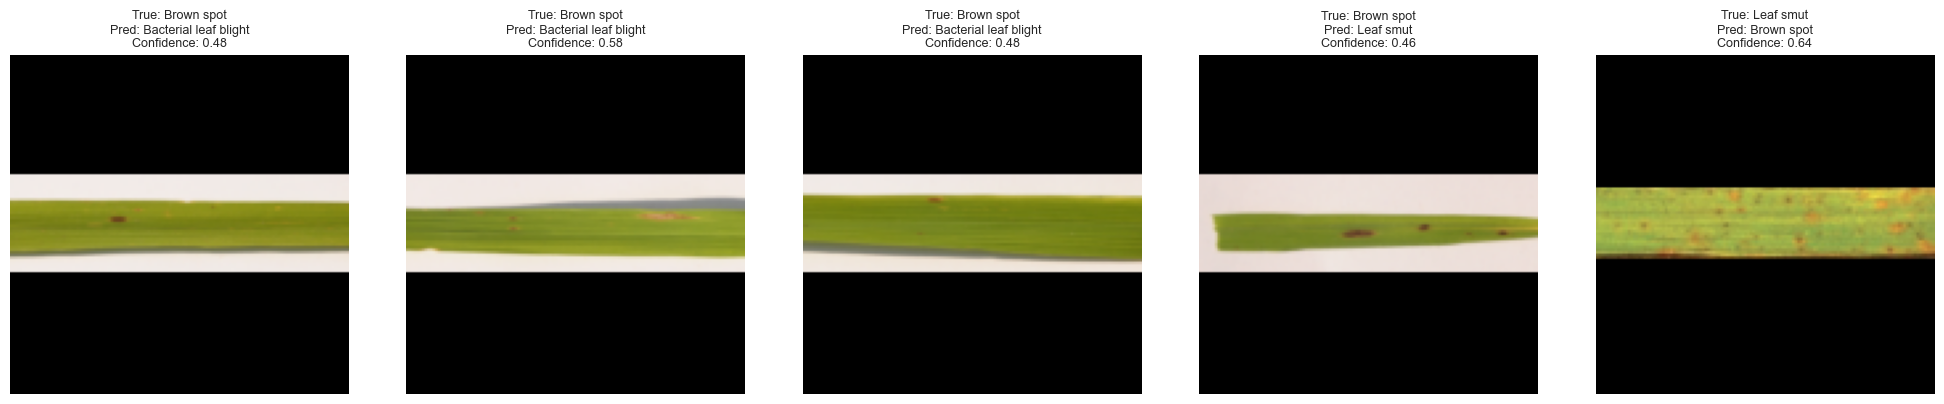

,file,true,predicted,confidence,width,height
0,DSC_0391.jpg,Brown spot,Bacterial leaf blight,0.480907,3081,897
1,DSC_0295.JPG,Brown spot,Bacterial leaf blight,0.584277,3081,897
2,DSC_0394.jpg,Brown spot,Bacterial leaf blight,0.479728,3081,897
3,DSC_0301.JPG,Brown spot,Leaf smut,0.462515,3081,897
4,DSC_0500.jpg,Leaf smut,Brown spot,0.641775,376,80


In [15]:
test_prob,test_pred=test_predictions[selected_name]
wrong=np.flatnonzero(test_pred!=y_test)
print(f"Misclassified test images: {len(wrong)} / {len(y_test)}")
if len(wrong):
    fig,axes=plt.subplots(1,len(wrong),figsize=(4*len(wrong),4)); axes=np.atleast_1d(axes)
    report=[]
    for ax,i in zip(axes,wrong):
        original=int(test_idx[i]); ax.imshow(X_test[i]); ax.axis("off")
        ax.set_title(f"True: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[test_pred[i]]}\nConfidence: {test_prob[i].max():.2f}",fontsize=9)
        report.append({"file":Path(paths[original]).name,"true":CLASS_NAMES[y_test[i]],"predicted":CLASS_NAMES[test_pred[i]],"confidence":float(test_prob[i].max()),"width":int(df.iloc[original].width),"height":int(df.iloc[original].height)})
    plt.tight_layout(); plt.show(); display(pd.DataFrame(report))
else: print("No errors on this split; the small test set still does not prove perfect generalization.")


## 10. Challenges and mitigations report

This report separates observed evidence from general risks that need further measurement.


In [16]:
challenges=pd.DataFrame([
 {"challenge":"Very small dataset","evidence":f"{len(df)} images; {len(y_test)} test cases","mitigation":"Transfer learning and mild augmentation; collect independent field images; use grouped or repeated validation."},
 {"challenge":"Label wording mismatch","evidence":"Brief task says leaf blast; class list says Leaf smut.","mitigation":"Use verified folder labels; document discrepancy; do not relabel without clarification."},
 {"challenge":"Image quality / framing","evidence":f"{df[['width','height']].drop_duplicates().shape[0]} unique dimensions; see plots and gallery.","mitigation":"RGB conversion and aspect-preserving padding; inspect samples and errors; avoid aggressive crops."},
 {"challenge":"Overfitting / score instability","evidence":"Review learning curves and small validation/test supports above.","mitigation":"Frozen-head training, limited fine-tuning, dropout, early stopping; repeat evaluation."},
 {"challenge":"Domain shift","evidence":"Not measurable from one supplied image collection.","mitigation":"External field test across locations, cultivars, phones and lighting."},
 {"challenge":"Class confusion / uncertain predictions","evidence":"Review per-class reports, confusion matrices and error gallery.","mitigation":"Agronomist label review; uncertainty threshold and human review."},])
display(challenges)


,challenge,evidence,mitigation
0,Very small dataset,119 images; 18 test cases,Transfer learning and mild augmentation; colle...
1,Label wording mismatch,Brief task says leaf blast; class list says Le...,Use verified folder labels; document discrepan...
2,Image quality / framing,34 unique dimensions; see plots and gallery.,RGB conversion and aspect-preserving padding; ...
3,Overfitting / score instability,Review learning curves and small validation/te...,"Frozen-head training, limited fine-tuning, dro..."
4,Domain shift,Not measurable from one supplied image collect...,"External field test across locations, cultivar..."
5,Class confusion / uncertain predictions,"Review per-class reports, confusion matrices a...",Agronomist label review; uncertainty threshold...


## 11. Save candidate and run summary

Save the validation-selected Keras model, class mapping, comparison and observed run metadata. Keep the notebook outputs and dataset version with these files for reproducibility.


In [17]:
model_path=OUTPUT_DIR/f"rice_leaf_{selected_name.lower()}_candidate.keras"
models[selected_name].save(model_path)
(OUTPUT_DIR/"class_names.txt").write_text("\n".join(CLASS_NAMES),encoding="utf-8")
comparison.to_csv(OUTPUT_DIR/"four_model_comparison.csv",index=False)
summary={"dataset_directory":str(DATASET_DIR.resolve()),"image_count":int(len(df)),"class_names":CLASS_NAMES,"class_counts":{k:int(v) for k,v in counts.items()},"seed":SEED,"image_size":list(IMG_SIZE),"selected_candidate":selected_name,"test_set_size":int(len(y_test)),"note":"Small single-split evaluation; external validation required before production use."}
(OUTPUT_DIR/"run_summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
print("Saved:",model_path.resolve()); print("Run artifacts:",OUTPUT_DIR.resolve())


Saved: C:\Users\DEENA\Downloads\outputs\rice_leaf_efficientnetb0_candidate.keras
Run artifacts: C:\Users\DEENA\Downloads\outputs


## 12. Conclusion and submission checklist

This notebook covers dataset analysis, three-class classification, augmentation and technique analysis, exactly four architecture approaches, model comparison, error analysis and a challenges report.

- [ ] Verify class folders and labels; resolve any uncertain labels before training.
- [ ] Record observed image counts, unreadable files, duplicates and dimension findings.
- [ ] Review representative originals and augmentation previews.
- [ ] Run all four models; retain comparison and per-class reports.
- [ ] Inspect the confusion matrices and every error.
- [ ] State the validation-selected candidate with the small-test-set caveat.
- [ ] Seek external evaluation across fields/devices before production use.
- [ ] Include the saved model, class_names.txt, four_model_comparison.csv and run_summary.json if required.

**Final note:** The brief describes 120 images (40 each), but this notebook reports observed files. It explicitly documents the leaf blast / Leaf smut wording conflict. No result is asserted until the notebook is run on the data.
